In [156]:
!pip install plotly

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.9 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.9 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.9 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.9 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.9 MB 378.2 kB/s eta 0:00:25
   -- ------------------------------------- 0.5/9.9 MB 378.2 kB/s eta 0:00:25
   -- ------------------------------------- 0.5/9.9 MB 378.2 kB/s eta 0:00:25
   -- ------------------------------------- 0.5/9.9 MB 378.2 kB/s eta 0:00:25
   --- ------------------------------------ 0.8/9.9 MB 356

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [157]:
import matplotlib.pyplot as plt 
import numpy as np
import pandas as pd
import seaborn as sns 
import plotly.express as px

## **EXCERCICE 1**

In [7]:
data = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML0232EN-SkillsNetwork/asset/iris_data.csv")
data.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [8]:
data.shape

(150, 5)

In [9]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [12]:
data.columns

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')

In [13]:
data.dtypes

sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

In [14]:
data.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [19]:
data['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [33]:
data.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [35]:
stats_df = data.describe()
stats_df = data.describe()
stats_df.loc['range'] = stats_df.loc['max'] - stats_df.loc['min']

out_fields = ['mean','25%','50%','75%', 'range']
stats_df = stats_df.loc[out_fields]
stats_df.rename({'50%': 'median'}, inplace=True)
stats_df

,sepal_length,sepal_width,petal_length,petal_width
mean,5.843333,3.054,3.758667,1.198667
25%,5.100000,2.800,1.600000,0.300000
median,5.800000,3.000,4.350000,1.300000
75%,6.400000,3.300,5.100000,1.800000
range,3.600000,2.400,5.900000,2.400000


In [40]:
data.groupby('species').mean()

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.006,3.418,1.464,0.244
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


In [41]:
data.groupby('species').median()

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.0,3.4,1.50,0.2
versicolor,5.9,2.8,4.35,1.3
virginica,6.5,3.0,5.55,2.0


In [44]:
data.groupby('species').agg(['mean', 'median'])
data.groupby('species').agg([np.mean , np.median])

sepal_length        sepal_width        petal_length         \
                   mean median        mean median         mean median   
species                                                                 
setosa            5.006    5.0       3.418    3.4        1.464   1.50   
versicolor        5.936    5.9       2.770    2.8        4.260   4.35   
virginica         6.588    6.5       2.974    3.0        5.552   5.55   

           petal_width         
                  mean median  
species                        
setosa           0.244    0.2  
versicolor       1.326    1.3  
virginica        2.026    2.0

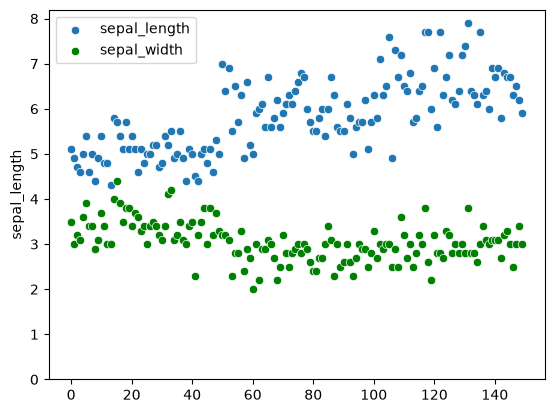

In [55]:
sns.scatterplot(data['sepal_length'], label="sepal_length")
sns.scatterplot(data['sepal_width'],color="green", label="sepal_width")
plt.ylim(0,)
plt.legend()
plt.show()

Text(0, 0.5, 'frequency')

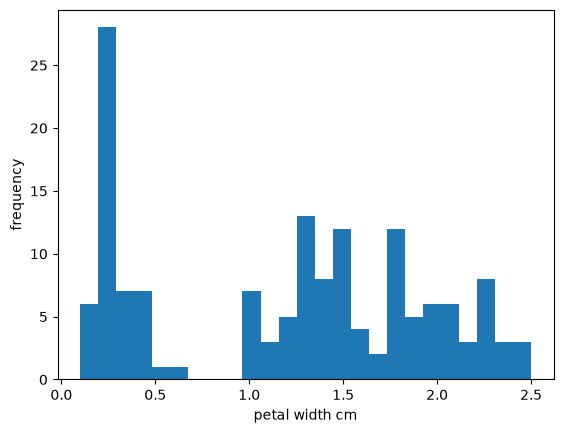

In [58]:
plt.hist(data['petal_width'], bins=25)
plt.xlabel("petal width cm")
plt.ylabel("frequency")

<Axes: ylabel='Frequency'>

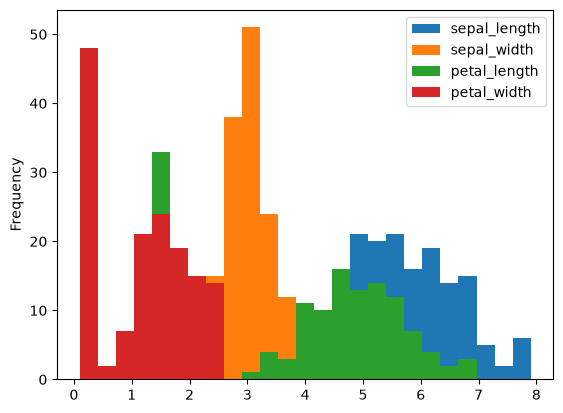

In [60]:
data.plot.hist(bins=25)

<Axes: >

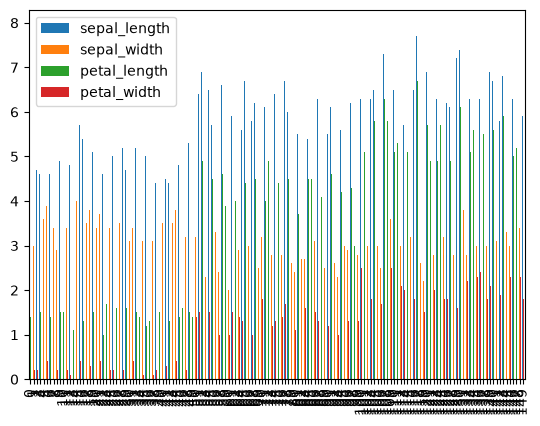

In [77]:
data.plot.bar()

array([[<Axes: title={'center': 'petal_length'}, xlabel='[species]'>,
        <Axes: title={'center': 'petal_width'}, xlabel='[species]'>],
       [<Axes: title={'center': 'sepal_length'}, xlabel='[species]'>,
        <Axes: title={'center': 'sepal_width'}, xlabel='[species]'>]],
      dtype=object)

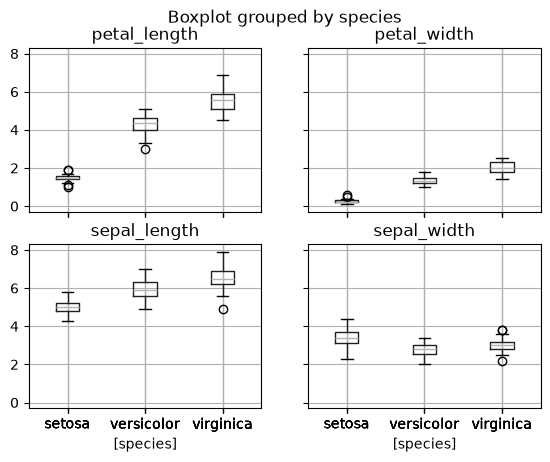

In [71]:
data.boxplot(by="species")

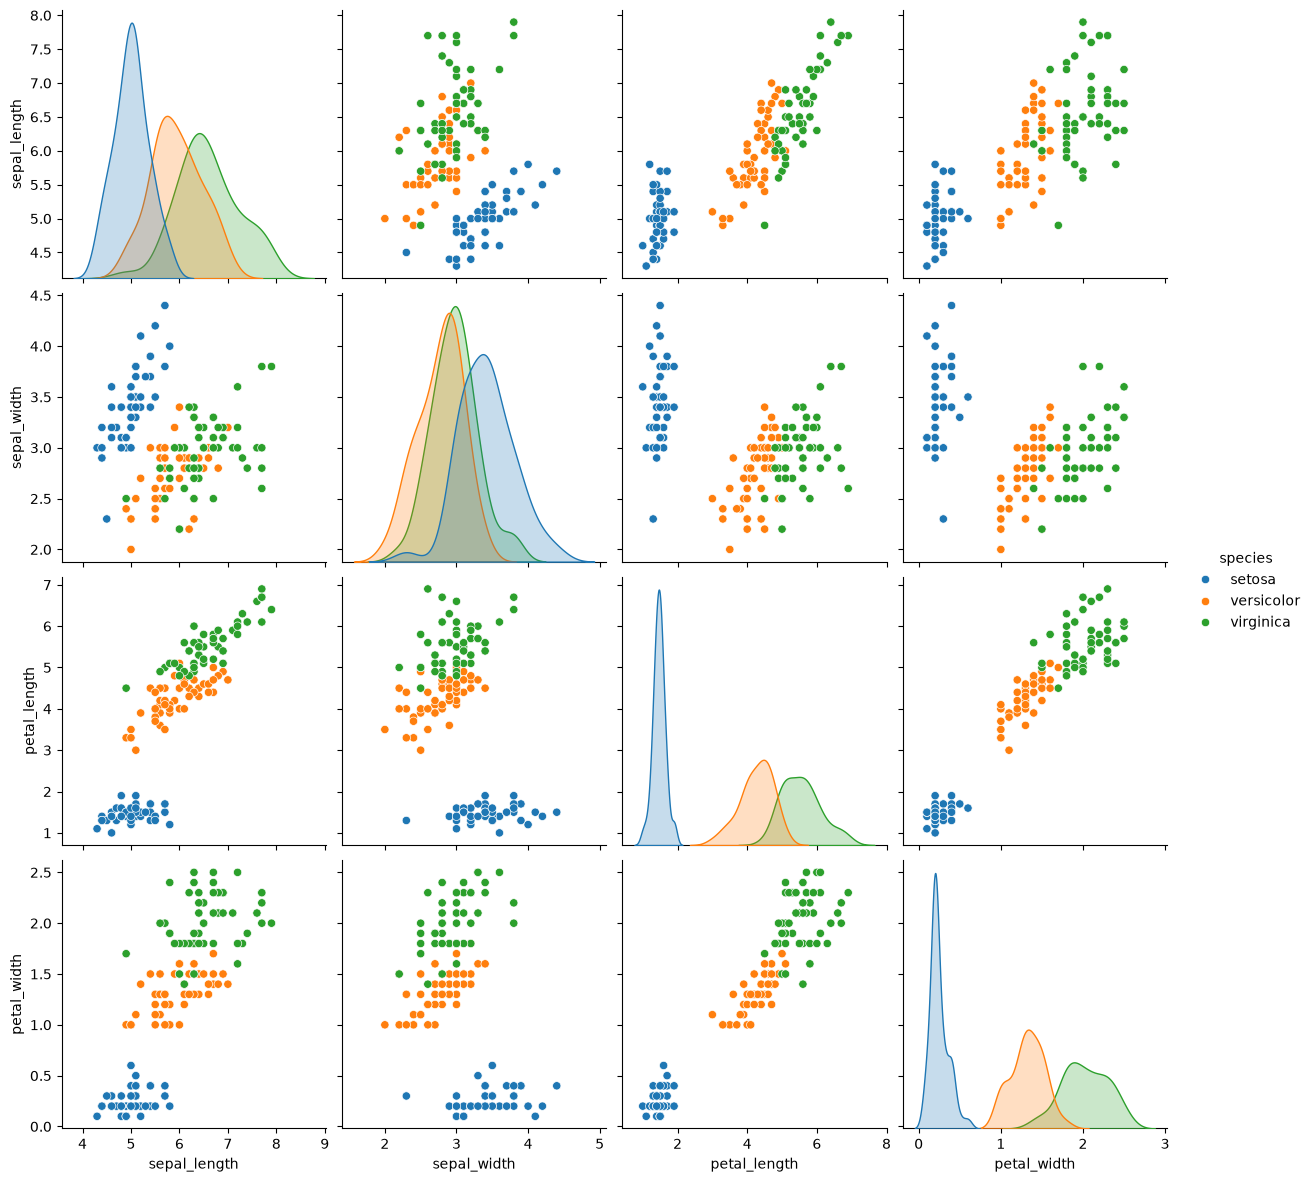

In [74]:
sns.pairplot(data, hue="species", height=3)

## **EXCERCICE 2**

In [78]:
gasoline = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML0232EN-SkillsNetwork/asset/18100001.csv")
gasoline.head()

,REF_DATE,GEO,DGUID,Type of fuel,UOM,UOM_ID,SCALAR_FACTOR,SCALAR_ID,VECTOR,COORDINATE,VALUE,STATUS,SYMBOL,TERMINATED,DECIMALS
0,Jan-79,"St. John's, Newfoundland and Labrador",2011S0503001,Regular unleaded gasoline at full service fill...,Cents per litre,57,units,0,v735046,2.1,26.0,NaN,NaN,t,1
1,Jan-79,"Charlottetown and Summerside, Prince Edward Is...",NaN,Regular unleaded gasoline at full service fill...,Cents per litre,57,units,0,v735056,3.1,24.6,NaN,NaN,t,1
2,Jan-79,"Halifax, Nova Scotia",2011S0503205,Regular unleaded gasoline at full service fill...,Cents per litre,57,units,0,v735057,4.1,23.4,NaN,NaN,t,1
3,Jan-79,"Saint John, New Brunswick",2011S0503310,Regular unleaded gasoline at full service fill...,Cents per litre,57,units,0,v735058,5.1,23.2,NaN,NaN,t,1
4,Jan-79,"Québec, Quebec",2011S0503421,Regular unleaded gasoline at full service fill...,Cents per litre,57,units,0,v735059,6.1,22.6,NaN,NaN,t,1


In [79]:
gasoline.describe()

,UOM_ID,SCALAR_ID,COORDINATE,VALUE,STATUS,SYMBOL,DECIMALS
count,41942.0,41942.0,41942.000000,41942.000000,0.0,0.0,41942.0
mean,57.0,0.0,10.902122,84.784858,NaN,NaN,1.0
std,0.0,0.0,5.196788,31.492697,NaN,NaN,0.0
min,57.0,0.0,2.100000,18.300000,NaN,NaN,1.0
25%,57.0,0.0,6.500000,58.200000,NaN,NaN,1.0
50%,57.0,0.0,11.100000,79.200000,NaN,NaN,1.0
75%,57.0,0.0,15.400000,110.900000,NaN,NaN,1.0
max,57.0,0.0,19.700000,191.600000,NaN,NaN,1.0


In [80]:
gasoline.dtypes

REF_DATE             str
GEO                  str
DGUID                str
Type of fuel         str
UOM                  str
UOM_ID             int64
SCALAR_FACTOR        str
SCALAR_ID          int64
VECTOR               str
COORDINATE       float64
VALUE            float64
STATUS           float64
SYMBOL           float64
TERMINATED           str
DECIMALS           int64
dtype: object

In [81]:
gasoline.isnull().sum()

REF_DATE             0
GEO                  0
DGUID             2491
Type of fuel         0
UOM                  0
UOM_ID               0
SCALAR_FACTOR        0
SCALAR_ID            0
VECTOR               0
COORDINATE           0
VALUE                0
STATUS           41942
SYMBOL           41942
TERMINATED       25378
DECIMALS             0
dtype: int64

In [83]:
gasoline['DGUID'].mode()[0]

'2011S0503421'

In [84]:
41942- 25378

16564

In [87]:
gasoline['TERMINATED']

0          t
1          t
2          t
3          t
4          t
        ... 
41937    NaN
41938    NaN
41939    NaN
41940    NaN
41941    NaN
Name: TERMINATED, Length: 41942, dtype: str

In [89]:
gasoline.shape

(41942, 15)

In [90]:
gasoline.info()

<class 'pandas.DataFrame'>
RangeIndex: 41942 entries, 0 to 41941
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   REF_DATE       41942 non-null  str    
 1   GEO            41942 non-null  str    
 2   DGUID          39451 non-null  str    
 3   Type of fuel   41942 non-null  str    
 4   UOM            41942 non-null  str    
 5   UOM_ID         41942 non-null  int64  
 6   SCALAR_FACTOR  41942 non-null  str    
 7   SCALAR_ID      41942 non-null  int64  
 8   VECTOR         41942 non-null  str    
 9   COORDINATE     41942 non-null  float64
 10  VALUE          41942 non-null  float64
 11  STATUS         0 non-null      float64
 12  SYMBOL         0 non-null      float64
 13  TERMINATED     16564 non-null  str    
 14  DECIMALS       41942 non-null  int64  
dtypes: float64(4), int64(3), str(8)
memory usage: 4.8 MB


In [91]:
gasoline.columns

Index(['REF_DATE', 'GEO', 'DGUID', 'Type of fuel', 'UOM', 'UOM_ID',
       'SCALAR_FACTOR', 'SCALAR_ID', 'VECTOR', 'COORDINATE', 'VALUE', 'STATUS',
       'SYMBOL', 'TERMINATED', 'DECIMALS'],
      dtype='str')

In [92]:
data = (gasoline[['REF_DATE','GEO','Type of fuel','VALUE']]).rename(columns={"REF_DATE" : "DATE", "Type of fuel" : "TYPE"})
data.head()

,DATE,GEO,TYPE,VALUE
0,Jan-79,"St. John's, Newfoundland and Labrador",Regular unleaded gasoline at full service fill...,26.0
1,Jan-79,"Charlottetown and Summerside, Prince Edward Is...",Regular unleaded gasoline at full service fill...,24.6
2,Jan-79,"Halifax, Nova Scotia",Regular unleaded gasoline at full service fill...,23.4
3,Jan-79,"Saint John, New Brunswick",Regular unleaded gasoline at full service fill...,23.2
4,Jan-79,"Québec, Quebec",Regular unleaded gasoline at full service fill...,22.6


In [97]:
data[['City', 'Province']] = data['GEO'].str.split(",", n=1, expand=True)
data.head()

,DATE,GEO,TYPE,VALUE,City,Province
0,Jan-79,"St. John's, Newfoundland and Labrador",Regular unleaded gasoline at full service fill...,26.0,St. John's,Newfoundland and Labrador
1,Jan-79,"Charlottetown and Summerside, Prince Edward Is...",Regular unleaded gasoline at full service fill...,24.6,Charlottetown and Summerside,Prince Edward Island
2,Jan-79,"Halifax, Nova Scotia",Regular unleaded gasoline at full service fill...,23.4,Halifax,Nova Scotia
3,Jan-79,"Saint John, New Brunswick",Regular unleaded gasoline at full service fill...,23.2,Saint John,New Brunswick
4,Jan-79,"Québec, Quebec",Regular unleaded gasoline at full service fill...,22.6,Québec,Quebec


In [104]:
data['DATE']= pd.to_datetime(data['DATE'], format='%b-%y')
data['Month'] = data['DATE'].dt.month_name().str.slice(stop=3)
data['Year'] = data['DATE'].dt.year
data

,DATE,GEO,TYPE,VALUE,City,Province,Month,Year
0,1979-01-01,"St. John's, Newfoundland and Labrador",Regular unleaded gasoline at full service fill...,26.0,St. John's,Newfoundland and Labrador,Jan,1979
1,1979-01-01,"Charlottetown and Summerside, Prince Edward Is...",Regular unleaded gasoline at full service fill...,24.6,Charlottetown and Summerside,Prince Edward Island,Jan,1979
2,1979-01-01,"Halifax, Nova Scotia",Regular unleaded gasoline at full service fill...,23.4,Halifax,Nova Scotia,Jan,1979
3,1979-01-01,"Saint John, New Brunswick",Regular unleaded gasoline at full service fill...,23.2,Saint John,New Brunswick,Jan,1979
4,1979-01-01,"Québec, Quebec",Regular unleaded gasoline at full service fill...,22.6,Québec,Quebec,Jan,1979
...,...,...,...,...,...,...,...,...
41937,2021-10-01,"Whitehorse, Yukon",Household heating fuel,140.6,Whitehorse,Yukon,Oct,2021
41938,2021-10-01,"Yellowknife, Northwest Territories",Regular unleaded gasoline at self service fill...,150.6,Yellowknife,Northwest Territories,Oct,2021
41939,2021-10-01,"Yellowknife, Northwest Territories",Premium unleaded gasoline at self service fill...,166.1,Yellowknife,Northwest Territories,Oct,2021
41940,2021-10-01,"Yellowknife, Northwest Territories",Diesel fuel at self service filling stations,149.8,Yellowknife,Northwest Territories,Oct,2021


In [106]:
data.describe(include="all")

,DATE,GEO,TYPE,VALUE,City,Province,Month,Year
count,41942,41942,41942,41942.000000,41942,41942,41942,41942.000000
unique,NaN,18,7,NaN,18,13,12,NaN
top,NaN,"Charlottetown and Summerside, Prince Edward Is...",Regular unleaded gasoline at full service fill...,NaN,Charlottetown and Summerside,Quebec,Jan,NaN
freq,NaN,2491,7086,NaN,2491,4982,3552,NaN
mean,2003-06-04 11:52:16.502789,NaN,NaN,84.784858,NaN,NaN,NaN,2002.968051
min,1979-01-01 00:00:00,NaN,NaN,18.300000,NaN,NaN,NaN,1979.000000
25%,1995-12-01 00:00:00,NaN,NaN,58.200000,NaN,NaN,NaN,1995.000000
50%,2003-05-01 00:00:00,NaN,NaN,79.200000,NaN,NaN,NaN,2003.000000
75%,2010-10-01 00:00:00,NaN,NaN,110.900000,NaN,NaN,NaN,2010.000000
max,2021-10-01 00:00:00,NaN,NaN,191.600000,NaN,NaN,NaN,2021.000000


In [107]:
data['GEO'].unique()

<StringArray>
[             'St. John's, Newfoundland and Labrador',
 'Charlottetown and Summerside, Prince Edward Island',
                               'Halifax, Nova Scotia',
                          'Saint John, New Brunswick',
                                     'Québec, Quebec',
                                   'Montréal, Quebec',
      'Ottawa-Gatineau, Ontario part, Ontario/Quebec',
                                   'Toronto, Ontario',
                               'Thunder Bay, Ontario',
                                 'Winnipeg, Manitoba',
                               'Regina, Saskatchewan',
                            'Saskatoon, Saskatchewan',
                                  'Edmonton, Alberta',
                                   'Calgary, Alberta',
                        'Vancouver, British Columbia',
                         'Victoria, British Columbia',
                                  'Whitehorse, Yukon',
                 'Yellowknife, Northwest Territorie

In [110]:
data['TYPE'].unique().tolist()

['Regular unleaded gasoline at full service filling stations',
 'Regular unleaded gasoline at self service filling stations',
 'Premium unleaded gasoline at full service filling stations',
 'Premium unleaded gasoline at self service filling stations',
 'Diesel fuel at full service filling stations',
 'Household heating fuel',
 'Diesel fuel at self service filling stations']

In [122]:
calgary = data[data['GEO'] == 'Calgary, Alberta']
calgary

,DATE,GEO,TYPE,VALUE,City,Province,Month,Year
13,1979-01-01,"Calgary, Alberta",Regular unleaded gasoline at full service fill...,18.7,Calgary,Alberta,Jan,1979
28,1979-02-01,"Calgary, Alberta",Regular unleaded gasoline at full service fill...,18.9,Calgary,Alberta,Feb,1979
43,1979-03-01,"Calgary, Alberta",Regular unleaded gasoline at full service fill...,18.9,Calgary,Alberta,Mar,1979
58,1979-04-01,"Calgary, Alberta",Regular unleaded gasoline at full service fill...,19.1,Calgary,Alberta,Apr,1979
73,1979-05-01,"Calgary, Alberta",Regular unleaded gasoline at full service fill...,19.2,Calgary,Alberta,May,1979
...,...,...,...,...,...,...,...,...
41855,2021-09-01,"Calgary, Alberta",Premium unleaded gasoline at self service fill...,156.6,Calgary,Alberta,Sep,2021
41856,2021-09-01,"Calgary, Alberta",Diesel fuel at self service filling stations,125.1,Calgary,Alberta,Sep,2021
41923,2021-10-01,"Calgary, Alberta",Regular unleaded gasoline at self service fill...,140.8,Calgary,Alberta,Oct,2021
41924,2021-10-01,"Calgary, Alberta",Premium unleaded gasoline at self service fill...,164.4,Calgary,Alberta,Oct,2021


In [121]:
df = data[data['Year'].astype('int') >= 2010]
df

,DATE,GEO,TYPE,VALUE,City,Province,Month,Year
30328,2010-01-01,"St. John's, Newfoundland and Labrador",Regular unleaded gasoline at full service fill...,112.4,St. John's,Newfoundland and Labrador,Jan,2010
30329,2010-01-01,"St. John's, Newfoundland and Labrador",Regular unleaded gasoline at self service fill...,109.8,St. John's,Newfoundland and Labrador,Jan,2010
30330,2010-01-01,"St. John's, Newfoundland and Labrador",Premium unleaded gasoline at full service fill...,118.4,St. John's,Newfoundland and Labrador,Jan,2010
30331,2010-01-01,"St. John's, Newfoundland and Labrador",Premium unleaded gasoline at self service fill...,115.7,St. John's,Newfoundland and Labrador,Jan,2010
30332,2010-01-01,"St. John's, Newfoundland and Labrador",Diesel fuel at full service filling stations,105.8,St. John's,Newfoundland and Labrador,Jan,2010
...,...,...,...,...,...,...,...,...
41937,2021-10-01,"Whitehorse, Yukon",Household heating fuel,140.6,Whitehorse,Yukon,Oct,2021
41938,2021-10-01,"Yellowknife, Northwest Territories",Regular unleaded gasoline at self service fill...,150.6,Yellowknife,Northwest Territories,Oct,2021
41939,2021-10-01,"Yellowknife, Northwest Territories",Premium unleaded gasoline at self service fill...,166.1,Yellowknife,Northwest Territories,Oct,2021
41940,2021-10-01,"Yellowknife, Northwest Territories",Diesel fuel at self service filling stations,149.8,Yellowknife,Northwest Territories,Oct,2021


In [136]:
calgary = data[data['Year'] >= 2000]
calgary

,DATE,GEO,TYPE,VALUE,City,Province,Month,Year
16168,2000-01-01,"St. John's, Newfoundland and Labrador",Regular unleaded gasoline at full service fill...,78.0,St. John's,Newfoundland and Labrador,Jan,2000
16169,2000-01-01,"St. John's, Newfoundland and Labrador",Regular unleaded gasoline at self service fill...,74.9,St. John's,Newfoundland and Labrador,Jan,2000
16170,2000-01-01,"St. John's, Newfoundland and Labrador",Premium unleaded gasoline at full service fill...,84.5,St. John's,Newfoundland and Labrador,Jan,2000
16171,2000-01-01,"St. John's, Newfoundland and Labrador",Premium unleaded gasoline at self service fill...,81.3,St. John's,Newfoundland and Labrador,Jan,2000
16172,2000-01-01,"St. John's, Newfoundland and Labrador",Diesel fuel at full service filling stations,69.2,St. John's,Newfoundland and Labrador,Jan,2000
...,...,...,...,...,...,...,...,...
41937,2021-10-01,"Whitehorse, Yukon",Household heating fuel,140.6,Whitehorse,Yukon,Oct,2021
41938,2021-10-01,"Yellowknife, Northwest Territories",Regular unleaded gasoline at self service fill...,150.6,Yellowknife,Northwest Territories,Oct,2021
41939,2021-10-01,"Yellowknife, Northwest Territories",Premium unleaded gasoline at self service fill...,166.1,Yellowknife,Northwest Territories,Oct,2021
41940,2021-10-01,"Yellowknife, Northwest Territories",Diesel fuel at self service filling stations,149.8,Yellowknife,Northwest Territories,Oct,2021


In [126]:
calgary = data[(data['GEO'] == "Toronto, Ontario") | (data['GEO'] == "Edmonton, Alberta") ]
calgary

,DATE,GEO,TYPE,VALUE,City,Province,Month,Year
7,1979-01-01,"Toronto, Ontario",Regular unleaded gasoline at full service fill...,23.0,Toronto,Ontario,Jan,1979
12,1979-01-01,"Edmonton, Alberta",Regular unleaded gasoline at full service fill...,18.3,Edmonton,Alberta,Jan,1979
22,1979-02-01,"Toronto, Ontario",Regular unleaded gasoline at full service fill...,23.2,Toronto,Ontario,Feb,1979
27,1979-02-01,"Edmonton, Alberta",Regular unleaded gasoline at full service fill...,18.5,Edmonton,Alberta,Feb,1979
37,1979-03-01,"Toronto, Ontario",Regular unleaded gasoline at full service fill...,23.2,Toronto,Ontario,Mar,1979
...,...,...,...,...,...,...,...,...
41903,2021-10-01,"Toronto, Ontario",Diesel fuel at self service filling stations,141.3,Toronto,Ontario,Oct,2021
41904,2021-10-01,"Toronto, Ontario",Household heating fuel,148.0,Toronto,Ontario,Oct,2021
41920,2021-10-01,"Edmonton, Alberta",Regular unleaded gasoline at self service fill...,138.3,Edmonton,Alberta,Oct,2021
41921,2021-10-01,"Edmonton, Alberta",Premium unleaded gasoline at self service fill...,159.6,Edmonton,Alberta,Oct,2021


In [140]:
exo2= data[(data["TYPE"] == "household heating fuel") & (data["City"] == "Vancouver") & (data["Year"] == 1990)]
exo2

,DATE,GEO,TYPE,VALUE,City,Province,Month,Year


In [139]:
exo2b= data[ (data["Year"] >= 1979) & (data["Year"] <= 2021) & (data["TYPE"] == "household heating fuel") & (data["City"] == "Vancouver")]
exo2b

,DATE,GEO,TYPE,VALUE,City,Province,Month,Year


In [143]:
gp=data.groupby('GEO')
gp.ngroups

18

In [151]:
data.groupby('Year')['VALUE'].mean()

Year
1979     23.604444
1980     28.068750
1981     38.002604
1982     44.701563
1983     47.904688
1984     50.442708
1985     53.899479
1986     48.405208
1987     49.758333
1988     49.217188
1989     51.700000
1990     55.048735
1991     56.527041
1992     54.633832
1993     54.334734
1994     54.247899
1995     56.177451
1996     58.134110
1997     59.182062
1998     56.247246
1999     58.743362
2000     72.207839
2001     72.403107
2002     70.312147
2003     75.541667
2004     82.960452
2005     96.328743
2006    101.209393
2007    105.258263
2008    123.340678
2009     96.969068
2010    106.369845
2011    126.790607
2012    130.380085
2013    129.677273
2014    133.169203
2015    110.366908
2016    101.790821
2017    112.852657
2018    129.408575
2019    125.776329
2020    107.617150
2021    133.990580
Name: VALUE, dtype: float64

In [152]:
data.groupby('Month')['VALUE'].max()

Month
Apr    187.8
Aug    188.3
Dec    158.5
Feb    168.0
Jan    162.0
Jul    191.6
Jun    183.2
Mar    171.8
May    189.3
Nov    162.2
Oct    184.9
Sep    179.3
Name: VALUE, dtype: float64

In [154]:
data.groupby(['Year', 'City'])['VALUE'].median()

Year  City                        
1979  Calgary                          19.15
      Charlottetown and Summerside     25.45
      Edmonton                         18.70
      Halifax                          24.00
      Montréal                         23.25
                                       ...  
2021  Vancouver                       151.10
      Victoria                        148.80
      Whitehorse                      142.25
      Winnipeg                        127.70
      Yellowknife                     138.65
Name: VALUE, Length: 751, dtype: float64

In [158]:
price_bycity = data.groupby(['Year', 'GEO'])['VALUE'].mean().reset_index(name ='Value').round(2)

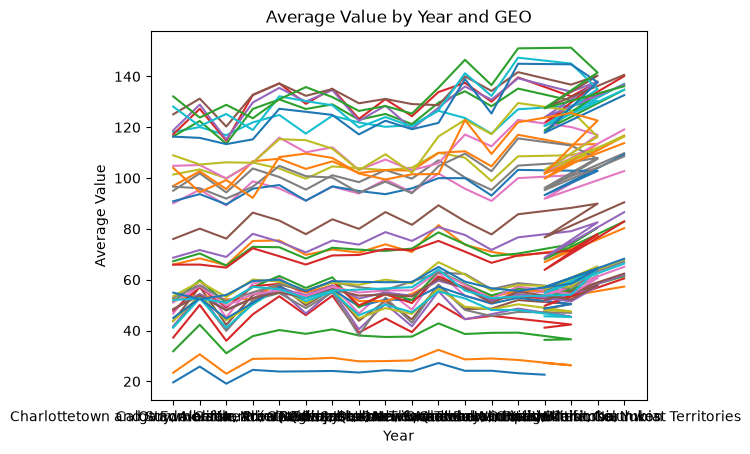

In [174]:
for geo in price_bycity["Year"].unique():
    subset = price_bycity[price_bycity["Year"] == geo]
    plt.plot(subset["GEO"], subset["Value"], label=geo)

plt.xlabel("Year")
plt.ylabel("Average Value")
plt.title("Average Value by Year and GEO")
plt.show()